# FAST, BRIEF and ORB in OpenCV

A simple walkthrough of three feature techniques:

| Technique | What it does |
|---|---|
| **FAST** | Detector: finds corner points |
| **BRIEF** | Descriptor: describes each point as a short binary string |
| **ORB** | Detector + descriptor: FAST + BRIEF with rotation and scale handling |

BRIEF lives in the contrib package: `pip install opencv-contrib-python`

## Setup

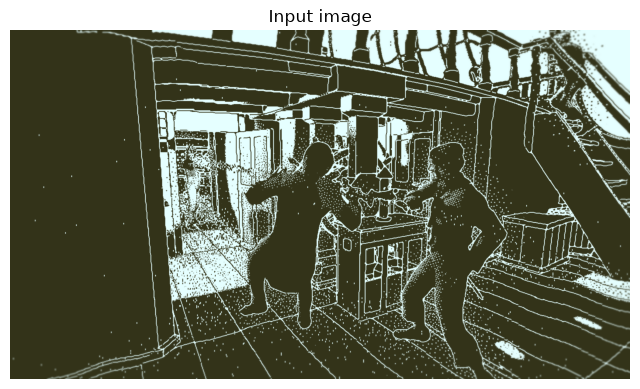

In [1]:
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = "images/scene1_angle1.png"

img = cv2.imread(IMAGE_PATH)
assert img is not None, f"Could not read {IMAGE_PATH}"
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


def show(image, title=""):
    """Display a BGR or grayscale image."""
    plt.figure(figsize=(8, 6))
    if image.ndim == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")
    plt.show()


show(img, "Input image")

## 1. FAST (Features from Accelerated Segment Test)

For each pixel `p`, FAST looks at 16 pixels on a circle around it.
If at least n neighbouring pixels in a row are all brighter than `p + threshold`
or all darker than `p - threshold`, then `p` is a corner. (normally n would be in the range 9–12)

- `threshold`: higher means fewer, stronger corners
- `nonmaxSuppression`: keeps only the strongest corner in each small neighbourhood

FAST only for keypoint detection.

FAST keypoints: 18402


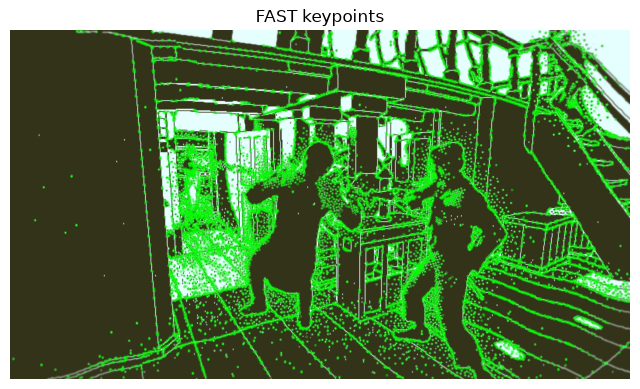

In [2]:
fast = cv2.FastFeatureDetector_create(threshold=20, nonmaxSuppression=True)
fast_kps = fast.detect(gray, None)

print("FAST keypoints:", len(fast_kps))
show(cv2.drawKeypoints(img, fast_kps, None, color=(0, 255, 0)), "FAST keypoints")

Try turning non-max suppression off to see how many extra (clustered) points appear:

Without NMS: 114999


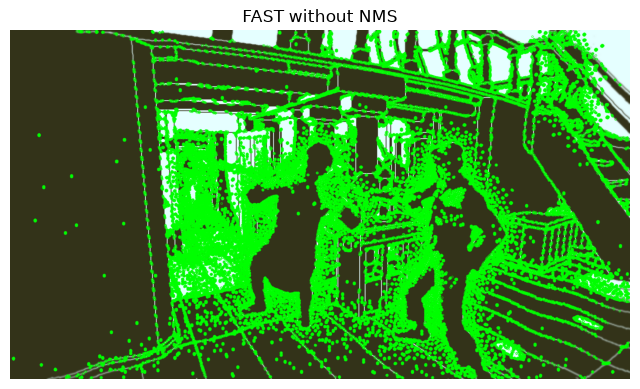

In [3]:
fast.setNonmaxSuppression(False)
fast_kps_no_nms = fast.detect(gray, None)
fast.setNonmaxSuppression(True)

print("Without NMS:", len(fast_kps_no_nms))
show(cv2.drawKeypoints(img, fast_kps_no_nms, None, color=(0, 255, 0)), "FAST without NMS")


### Strength: FAST is very fast

Time how long each detector takes to find keypoints on the same image.
SIFT is included as a well-known, slower detector for comparison.
The difference is clearer on larger images.


In [4]:

def average_ms(func, runs=10):
    """Average running time of func() in milliseconds."""
    func()  # warm-up run, not timed
    start = time.perf_counter()
    for _ in range(runs):
        func()
    return (time.perf_counter() - start) / runs * 1000


orb_detector = cv2.ORB_create()
sift = cv2.SIFT_create()

print(f"FAST: {average_ms(lambda: fast.detect(gray, None)):7.2f} ms")
print(f"ORB : {average_ms(lambda: orb_detector.detect(gray, None)):7.2f} ms")
print(f"SIFT: {average_ms(lambda: sift.detect(gray, None)):7.2f} ms")


FAST:    5.28 ms
ORB :   24.16 ms
SIFT:  270.15 ms


### Issue: FAST's corner score is weak

FAST scores a point by how much brighter or darker its circle is, not by how corner-like it is.
A tiny speck of noise also has a circle that is all brighter, so it can score as high as a real corner.

Scene 4 has clean corners plus many small specks and tick marks. We keep the top 100 FAST points,
ranked first by FAST's own score, then by the Harris corner score (which ORB uses).

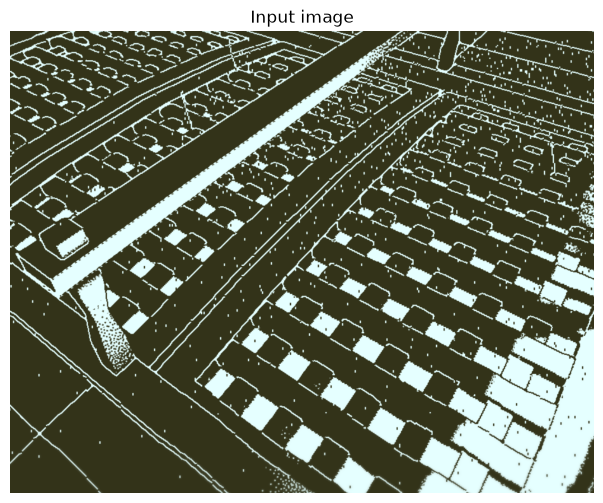

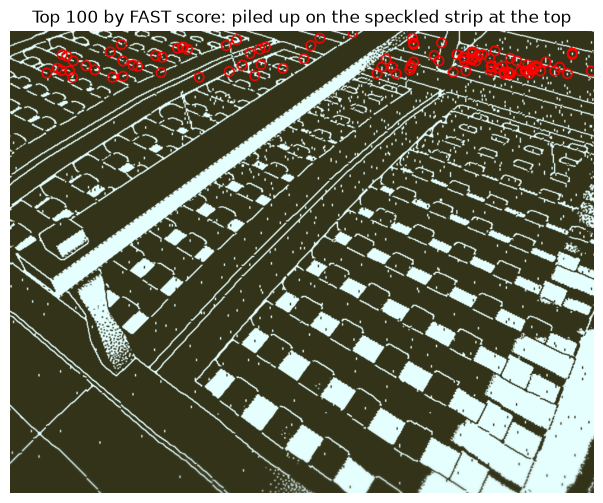

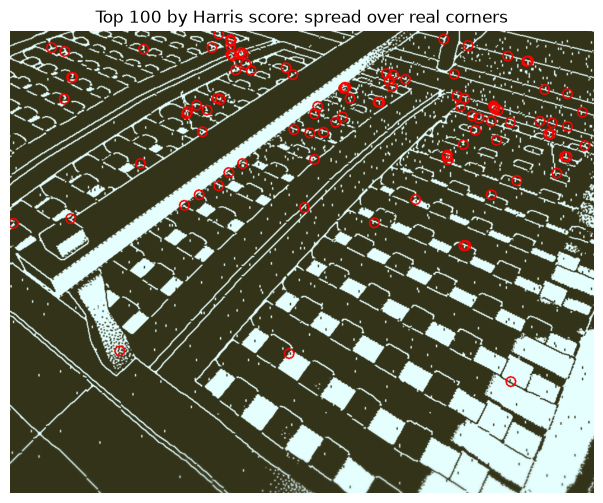

In [14]:
scene = cv2.imread("images/scene4_angle1.png")
scene_gray = cv2.cvtColor(scene, cv2.COLOR_BGR2GRAY)

scene_kps = fast.detect(scene_gray, None)
harris = cv2.cornerHarris(np.float32(scene_gray), blockSize=7, ksize=3, k=0.04)

top_fast = sorted(scene_kps, key=lambda k: k.response, reverse=True)[:100]
top_harris = sorted(scene_kps, key=lambda k: harris[int(k.pt[1]), int(k.pt[0])], reverse=True)[:100]


def mark(image, kps):
    out = image.copy()
    for k in kps:
        cv2.circle(out, (int(k.pt[0]), int(k.pt[1])), 9, (0, 0, 255), 2)
    return out

show(scene, "Input image")
show(mark(scene, top_fast), "Top 100 by FAST score: piled up on the speckled strip at the top")
show(mark(scene, top_harris), "Top 100 by Harris score: spread over real corners")

## 2. BRIEF (Binary Robust Independent Elementary Features)

BRIEF describes the area around a keypoint by comparing pairs of pixels:
`bit = 1 if I(a) < I(b) else 0`. With 256 pairs you get a 256-bit (32-byte) descriptor.

Binary descriptors are compared with the Hamming distance (the number of different bits), which is very fast.

BRIEF only for describing points, so we give it the keypoints found by FAST.

How the pairs are chosen: BRIEF picks its pixel pairs at random once, mostly near the keypoint centre, and then uses that same fixed set for every keypoint so descriptors can be compared bit by bit.

for example, the following two descriptors differ in 3 bits:

```
descriptor1 = 10101010101010101010101010101010
descriptor2 = 10101010101010101110101010101010
Hamming distance = 3
```

In [6]:
brief = cv2.xfeatures2d.BriefDescriptorExtractor_create()
brief_kps, brief_desc = brief.compute(gray, fast_kps) # We use the keypoints found by FAST to compute BRIEF descriptors.
# in brief.compute, points too close to the border are dropped
print("Keypoints described:", len(brief_kps))   
print("Descriptor array shape:", brief_desc.shape)  # (number of keypoints, 32 bytes)
print("First descriptor as bits:")
print(np.unpackbits(brief_desc[0]))

Keypoints described: 17928
Descriptor array shape: (17928, 32)
First descriptor as bits:
[0 1 0 1 1 1 0 0 0 1 0 0 0 1 1 0 1 0 1 0 0 1 0 0 0 0 0 1 0 1 0 1 1 1 1 1 0
 1 1 1 1 0 1 1 0 1 1 1 0 0 1 1 1 1 0 0 0 1 0 0 1 1 0 1 1 1 1 0 1 1 1 1 1 0
 0 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0 0 1 0 1 0 0 0 0 1 1 0 0 0 0 1 1 1 1 1 0 1
 0 1 1 1 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 0 1 0 0 1 1 1 0 1 1 1 0 1 1 0 1 0 1
 0 0 0 0 1 0 1 0 1 1 0 0 1 0 1 0 1 1 1 0 0 1 0 0 1 1 0 1 1 0 0 1 1 1 0 0 0
 1 1 0 1 0 1 0 1 1 0 1 1 1 1 1 0 0 0 1 0 0 0 1 1 0 1 1 1 0 0 0 1 1 0 0 1 0
 1 0 1 1 0 0 1 0 1 0 0 0 1 0 1 0 0 0 0 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1]



### Strength: BRIEF uses very little memory

Compare BRIEF with SIFT's descriptor (128 floats) on the same keypoints.


In [7]:

_, sift_desc = sift.compute(gray, brief_kps)

print(f"BRIEF: {brief_desc.shape[1] * brief_desc.itemsize:4d} bytes per keypoint, "
      f"{brief_desc.nbytes / 1024:7.1f} KB in total")
print(f"SIFT : {sift_desc.shape[1] * sift_desc.itemsize:4d} bytes per keypoint, "
      f"{sift_desc.nbytes / 1024:7.1f} KB in total")


BRIEF:   32 bytes per keypoint,   560.2 KB in total
SIFT :  512 bytes per keypoint,  8964.0 KB in total



### Testing FAST + BRIEF on a changed image

To test matching, we rotate or resize the image ourselves, so we know exactly where every point should end up
(the matrix `M`). A match counts as correct if it lands within 3 pixels of that spot.


In [8]:
matcher = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)


def fast_brief(image):
    return brief.compute(image, fast.detect(image, None))


def rotate(image, angle):
    h, w = image.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    return cv2.warpAffine(image, M, (w, h)), M


def resize(image, scale):
    M = np.array([[scale, 0, 0], [0, scale, 0]])
    return cv2.resize(image, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA), M


def test_matching(features, image2, M):
    """Match gray against image2 and count how many matches land where M says they should."""
    k1, d1 = features(gray)
    k2, d2 = features(image2)
    matches = matcher.match(d1, d2)
    correct = 0
    for m in matches:
        x, y = k1[m.queryIdx].pt
        expected = M @ [x, y, 1]
        if np.linalg.norm(expected - k2[m.trainIdx].pt) < 3:
            correct += 1
    return correct, len(matches)


def show_matches(features, image2, title, n=50):
    k1, d1 = features(gray)
    k2, d2 = features(image2)
    matches = sorted(matcher.match(d1, d2), key=lambda m: m.distance)[:n]
    show(cv2.drawMatches(gray, k1, image2, k2, matches, None, flags=2), title)



### Issue: BRIEF fails with rotation

BRIEF's pixel pairs are fixed to the image axes. When the image rotates, each pair compares different
pixels, so the bits change and matching breaks down after roughly 15–30°.


  0°: 17918 / 17918 correct (100%)
 15°:  3330 /  5576 correct (60%)
 30°:    20 /  2752 correct (1%)
 45°:     0 /  2387 correct (0%)


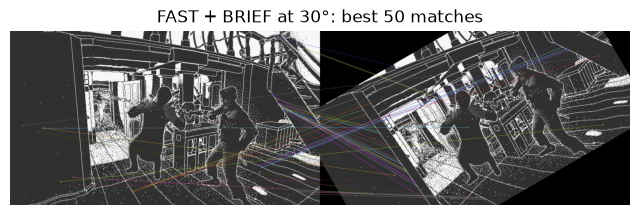

In [9]:

for angle in [0, 15, 30, 45]:
    correct, total = test_matching(fast_brief, *rotate(gray, angle))
    print(f"{angle:3d}°: {correct:5d} / {total:5d} correct ({correct / max(total, 1):.0%})")

show_matches(fast_brief, rotate(gray, 30)[0], "FAST + BRIEF at 30°: best 50 matches")



### Issue: FAST and BRIEF work at a single scale

FAST always uses a radius-3 circle and BRIEF a fixed-size patch. When the image is resized,
the same corner covers a different number of pixels, so both the detections and the descriptors change.


In [10]:

for scale in [0.5, 0.75, 1.0, 1.5, 2.0]:
    correct, total = test_matching(fast_brief, *resize(gray, scale))
    print(f"x{scale:4}: {correct:5d} / {total:5d} correct ({correct / max(total, 1):.0%})")


x 0.5:   138 /  2122 correct (7%)
x0.75:  3016 /  4627 correct (65%)
x 1.0: 17918 / 17918 correct (100%)
x 1.5:   809 /  4655 correct (17%)
x 2.0:    58 /  4845 correct (1%)


## 3. ORB (Oriented FAST and Rotated BRIEF)

ORB combines the two and fixes their weaknesses:

- Detector: FAST on an image pyramid (several scales), keeping the best corners by Harris score
- Orientation: each keypoint gets an angle from its intensity centroid
- Descriptor: BRIEF rotated by that angle (rBRIEF), so it works on rotated images

The circles below show each keypoint's size (scale), and the line shows its orientation.

ORB keypoints: 500
Descriptor array shape: (500, 32)


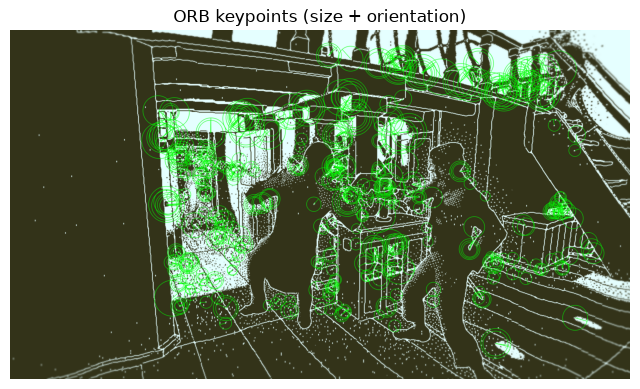

In [11]:
orb = cv2.ORB_create(nfeatures=500)
orb_kps, orb_desc = orb.detectAndCompute(gray, None)

print("ORB keypoints:", len(orb_kps))
print("Descriptor array shape:", orb_desc.shape)
show(cv2.drawKeypoints(img, orb_kps, None, color=(0, 255, 0),
                       flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS),
     "ORB keypoints (size + orientation)")


### ORB fixes these issues

- Weak corner score: ORB ranks FAST corners by the Harris score (`scoreType=cv2.ORB_HARRIS_SCORE`, the default), as in the FAST section.
- Rotation: rotated BRIEF follows each keypoint's angle.
- Scale: the image pyramid finds corners at several sizes.

Same rotation and scale tests as in the BRIEF section, now with ORB:


In [12]:
def orb_features(image):
    return orb.detectAndCompute(image, None)


print("Rotation")
for angle in [0, 15, 30, 45]:
    correct, total = test_matching(orb_features, *rotate(gray, angle))
    print(f"{angle:3d}°: {correct:5d} / {total:5d} correct ({correct / max(total, 1):.0%})")

print("Scale")
for scale in [0.5, 0.75, 1.0, 1.5, 2.0]:
    correct, total = test_matching(orb_features, *resize(gray, scale))
    print(f"x{scale:4}: {correct:5d} / {total:5d} correct ({correct / max(total, 1):.0%})")

Rotation
  0°:   500 /   500 correct (100%)
 15°:   191 /   232 correct (82%)
 30°:   179 /   230 correct (78%)
 45°:   174 /   231 correct (75%)
Scale
x 0.5:   124 /   184 correct (67%)
x0.75:   192 /   230 correct (83%)
x 1.0:   500 /   500 correct (100%)
x 1.5:   122 /   198 correct (62%)
x 2.0:    80 /   164 correct (49%)


### ORB on real photos from two angles

Each scene was captured from two camera angles. Here we don't know exactly where each point should land,
so we clean the matches in two steps:

1. Ratio test: keep a match only if it is clearly better than the second-best candidate.
2. RANSAC: keep only matches that agree with one consistent camera movement.

images/scene1_angle1.png vs images/scene1_angle2.png: 90 after ratio test, 38 after RANSAC


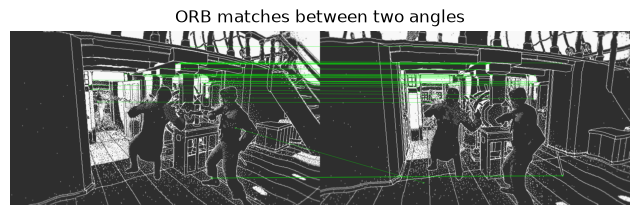

images/scene2_angle1.png vs images/scene2_angle2.png: 222 after ratio test, 59 after RANSAC


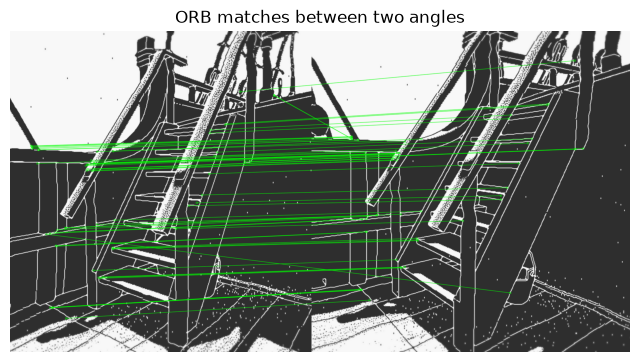

In [15]:
def match_two_angles(path1, path2, n_features=5000):
    image1 = cv2.imread(path1, cv2.IMREAD_GRAYSCALE)
    image2 = cv2.imread(path2, cv2.IMREAD_GRAYSCALE)

    orb_many = cv2.ORB_create(nfeatures=n_features)  # big photos, so allow more keypoints
    k1, d1 = orb_many.detectAndCompute(image1, None)
    k2, d2 = orb_many.detectAndCompute(image2, None)

    # 1. Ratio test
    pairs = cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(d1, d2, k=2)
    good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < 0.75 * p[1].distance]

    # 2. RANSAC
    pts1 = np.float32([k1[m.queryIdx].pt for m in good])
    pts2 = np.float32([k2[m.trainIdx].pt for m in good])
    _, mask = cv2.findFundamentalMat(pts1, pts2, cv2.FM_RANSAC, 3.0)
    consistent = [m for m, keep in zip(good, mask.ravel()) if keep]

    print(f"{path1} vs {path2}: {len(good)} after ratio test, {len(consistent)} after RANSAC")
    show(cv2.drawMatches(image1, k1, image2, k2, consistent, None, matchColor=(0, 255, 0), flags=2),
         "ORB matches between two angles")


match_two_angles("images/scene1_angle1.png", "images/scene1_angle2.png")
match_two_angles("images/scene2_angle1.png", "images/scene2_angle2.png")